# Task 1.4 — Validación contra la teoría

In [1]:
# --- Parámetros del grupo ---
import math
g = 3                                   # <-- número de grupo (cambiar aquí)
mu = 0.25
lam = 3.0 + 0.2 * ((g - 1) % 5)
c = 17 + ((g - 1) % 3)
a = lam / mu
rho = a / c
k_off = math.ceil(c - a) + 3
Tb = 7
print(f"Grupo {g}: lambda={lam:.1f}/día, c={c}, a={a:.2f}, rho={rho:.4f}, k_off={k_off}, Tb={Tb} días")

import numpy as np

def erlang_b(c, a):
    """Recurrencia: B(0)=1;  B(k) = a B(k-1) / (k + a B(k-1))"""
    B = 1.0
    for k in range(1, c + 1):
        B = a * B / (k + a * B)
    return B

def erlang_c_direct(c, a):
    """C(c,a) = [a^c/c! /(1-rho)] / [sum_{k<c} a^k/k! + a^c/c! /(1-rho)]  (estable vía logs)"""
    from math import lgamma, log, exp
    rho = a / c
    terms = [exp(k*log(a) - lgamma(k+1)) for k in range(c)]
    top = exp(c*log(a) - lgamma(c+1)) / (1 - rho)
    return top / (sum(terms) + top)

def theory_wait(lam, mu, c):
    a = lam / mu; rho = a / c
    assert rho < 1
    B = erlang_b(c, a)
    C = B / (1 - rho * (1 - B))             # Erlang C a partir de Erlang B
    Lq = C * rho / (1 - rho)
    Wq = Lq / lam                            # = C/(c mu - lam)
    W = Wq + 1 / mu
    L = Lq + a
    return dict(a=a, rho=rho, C=C, Lq=Lq, Wq_h=Wq*24, W_h=W*24, Wq=Wq, W=W, L=L, util=rho, Pwait=C)

def theory_loss(lam, mu, c):
    a = lam / mu
    B = erlang_b(c, a)
    lam_eff = lam * (1 - B)
    L = lam_eff / mu                         # = a (1-B)
    return dict(B=B, lam_eff=lam_eff, L=L, util=L / c, W=1/mu, Pblock=B)


import heapq, itertools
from collections import deque
import numpy as np
from scipy import stats

def simulate(lam, mu, c, T, warmup=0.0, seed=None, wait=True,
             inter_fn=None, serv_fn=None, sample_dt=None, _bugs=()):
    """Simulación de eventos discretos con lista de eventos (heap). Tiempo en días.
    wait=True  -> M/M/c   (cola infinita FIFO)
    wait=False -> M/M/c/c (si no hay cama, el paciente se pierde)
    inter_fn / serv_fn: generadores alternativos (para pruebas deterministas).
    _bugs: SOLO para pruebas de mutación (inyectan fallas conocidas)."""
    rng = np.random.default_rng(seed)
    ia = inter_fn or (lambda: rng.exponential(1.0 / lam))
    sv = serv_fn or (lambda: rng.exponential(1.0 / mu))
    if 'no_warmup' in _bugs:
        warmup = 0.0
    ev, cnt = [], itertools.count()
    heapq.heappush(ev, (ia(), next(cnt), 'A', None))
    heapq.heappush(ev, (T, next(cnt), 'END', None))
    if warmup > 0:
        heapq.heappush(ev, (warmup, next(cnt), 'WARM', None))

    busy, q = 0, deque()                       # q: [t_llegada, contado, t_cabeza]
    last, meas = 0.0, warmup <= 0
    aL = aLq = aB = 0.0                        # integrales ponderadas por duración
    naive_sum = naive_n = 0
    n_arr = n_blk = n_delayed = 0
    waits, soj = [], []
    S_n, S_q, next_s = [], [], 0.0

    def acc(t):
        nonlocal aL, aLq, aB
        dt = t - last
        aL += (busy + len(q)) * dt; aLq += len(q) * dt; aB += busy * dt

    while ev:
        t, _, kind, data = heapq.heappop(ev)
        if sample_dt:
            while next_s <= min(t, T):
                S_n.append(busy + len(q)); S_q.append(len(q)); next_s += sample_dt
        if kind == 'END':
            if meas and 'no_final_segment' not in _bugs:
                acc(T)                         # cierra el último tramo hasta T
            break
        if meas:
            acc(t)
        last = t
        if kind == 'WARM':
            meas = True
        elif kind == 'A':
            heapq.heappush(ev, (t + ia(), next(cnt), 'A', None))
            counted = meas                     # la llegada pertenece a la ventana de medición
            n_arr += counted
            if busy < c:
                busy += 1
                if counted: waits.append(0.0)
                heapq.heappush(ev, (t + sv(), next(cnt), 'D', (t, counted)))
            elif wait:
                if counted: n_delayed += 1
                q.append([t, counted, t])
            else:
                n_blk += counted
        elif kind == 'D':
            arr, counted = data
            busy -= 1
            if counted: soj.append(t - arr)    # tiempo en sistema (llegada -> salida)
            if q:
                a_t, cn, head = q.popleft()
                busy += 1
                w = (t - head) if 'wait_from_head' in _bugs else (t - a_t)   # espera desde LLEGADA
                if cn: waits.append(w)
                heapq.heappush(ev, (t + sv(), next(cnt), 'D', (a_t, cn)))
                if q: q[0][2] = t
        if meas:
            naive_sum += busy + len(q); naive_n += 1

    span = T - warmup
    L = aL / span
    if 'naive_L' in _bugs:
        L = naive_sum / max(naive_n, 1)
    admitted = n_arr - n_blk
    return dict(L=L, Lq=aLq / span, util=aB / span / c,
                Pwait=(n_delayed / n_arr) if (wait and n_arr) else (0.0 if wait else np.nan),
                Pblock=(n_blk / n_arr) if (n_arr and not wait) else (np.nan if wait else 0.0),
                Wq=float(np.mean(waits)) if waits else np.nan,
                W=float(np.mean(soj)) if soj else np.nan,
                lam_eff=admitted / span, n_arr=n_arr, n_blk=n_blk, span=span,
                waits=np.array(waits), soj=np.array(soj),
                S_n=np.array(S_n), S_q=np.array(S_q))

def run_reps(R, lam, mu, c, T, warmup, wait=True, master_seed=2026, _bugs=(), **kw):
    """R réplicas con flujos de números aleatorios independientes (SeedSequence.spawn)."""
    seeds = np.random.SeedSequence(master_seed).spawn(R)
    if 'same_seed' in _bugs:
        seeds = [master_seed] * R
    return [simulate(lam, mu, c, T, warmup, seed=s, wait=wait, _bugs=_bugs, **kw) for s in seeds]

def ci95(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    m = x.mean(); h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return m, h


Grupo 3: lambda=3.4/día, c=19, a=13.60, rho=0.7158, k_off=9, Tb=7 días


In [2]:
import matplotlib.pyplot as plt, pandas as pd
tw, tl = theory_wait(lam, mu, c), theory_loss(lam, mu, c)

## Calentamiento: gráfico del promedio móvil (Welch, 30 réplicas, muestreo cada 0.5 día)

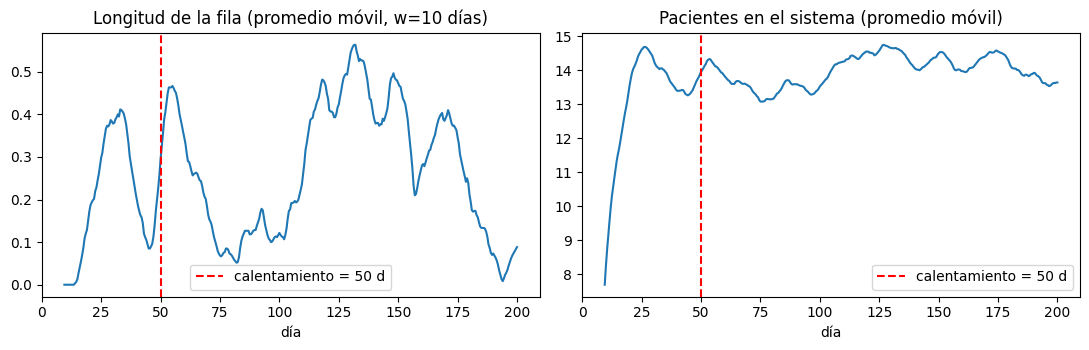

L(t) medio en [150,200]: 14.03366336633663  | media en [0,10): 7.686666666666666
Sesgo del arranque vacío ~ a*exp(-mu*t): t=50 -> 5.0682483140269925e-05 camas


In [3]:
dt_s, Tpil, Rp = 0.5, 200.0, 30
pil = run_reps(Rp, lam, mu, c, Tpil, 0.0, wait=True, master_seed=7, sample_dt=dt_s)
n = min(len(x['S_n']) for x in pil)
Lbar = np.mean([x['S_n'][:n] for x in pil], axis=0)
Qbar = np.mean([x['S_q'][:n] for x in pil], axis=0)
tt = np.arange(n) * dt_s
def mov(x, w): return np.convolve(x, np.ones(w)/w, mode='valid')
w = 20
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(tt[w-1:], mov(Qbar, w)); ax[0].set_title("Longitud de la fila (promedio móvil, w=10 días)")
ax[1].plot(tt[w-1:], mov(Lbar, w)); ax[1].set_title("Pacientes en el sistema (promedio móvil)")
for a_ in ax: a_.axvline(50, color='r', ls='--', label='calentamiento = 50 d'); a_.set_xlabel("día"); a_.legend()
plt.tight_layout(); plt.savefig("welch.png", dpi=110); plt.show()
print("L(t) medio en [150,200]:", Lbar[tt>=150].mean(), " | media en [0,10):", Lbar[tt<10].mean())
print("Sesgo del arranque vacío ~ a*exp(-mu*t): t=50 ->", a*np.exp(-mu*50), "camas")

**Justificación:** arrancando vacío, $E[N(t)]$ converge como $a(1-e^{-\mu t})$ (con $\rho<1$ y $c=19$ el sistema es casi $M/M/\infty$). A 50 días el sesgo residual es $\approx 10^{-5}$ camas. Horizonte: $T=5000$ días (≈1250 estancias medias) para que el semi-ancho del IC de $P(\text{bloqueo})$ y $W_q$ sea pequeño.

In [4]:
T, WU, R = 5000.0, 50.0, 30
repW = run_reps(R, lam, mu, c, T, WU, wait=True, master_seed=2026)
repL = run_reps(R, lam, mu, c, T, WU, wait=False, master_seed=4052)

def tabla(reps, th, rows):
    out = []
    for lab, key, thv, f in rows:
        m, h = ci95([f(x) for x in reps])
        out.append(dict(medida=lab, media=m, IC_low=m-h, IC_high=m+h, teoría=thv, dentro=(m-h <= thv <= m+h)))
    return pd.DataFrame(out).set_index('medida')

filasW = [("L", 'L', tw['L'], lambda x: x['L']), ("Lq", 'Lq', tw['Lq'], lambda x: x['Lq']),
          ("Wq [h]", 'Wq', tw['Wq_h'], lambda x: x['Wq']*24), ("W [h]", 'W', tw['W_h'], lambda x: x['W']*24),
          ("utilización", 'u', tw['util'], lambda x: x['util']), ("P(esperar)", 'Pw', tw['Pwait'], lambda x: x['Pwait'])]
filasL = [("L (camas ocupadas)", 'L', tl['L'], lambda x: x['L']), ("utilización", 'u', tl['util'], lambda x: x['util']),
          ("P(bloqueo)", 'B', tl['B'], lambda x: x['Pblock']), ("lambda_ef", 'le', tl['lam_eff'], lambda x: x['lam_eff'])]
print("== M/M/c ==");   display(tabla(repW, tw, filasW))
print("== M/M/c/c =="); display(tabla(repL, tl, filasL))

== M/M/c ==


,media,IC_low,IC_high,teoría,dentro
medida,,,,,
L,13.874132,13.808188,13.940076,13.903111,True
Lq,0.284900,0.267086,0.302715,0.303111,False
Wq [h],2.008389,1.885924,2.130854,2.139606,False
W [h],97.797489,97.478156,98.116822,98.139606,False
utilización,0.715223,0.712389,0.718057,0.715789,True
P(esperar),0.116871,0.112533,0.121209,0.120353,True


== M/M/c/c ==


,media,IC_low,IC_high,teoría,dentro
medida,,,,,
L (camas ocupadas),13.113634,13.072297,13.154972,13.090951,True
utilización,0.690191,0.688016,0.692367,0.688997,True
P(bloqueo),0.037468,0.036220,0.038715,0.037430,True
lambda_ef,3.273926,3.262374,3.285478,3.272738,True


**Nota sobre Lq, Wq y W:** con la semilla de la tabla estas tres medidas (casi la misma señal: $W_q=L_q/\lambda$, $W=W_q+1/\mu$) quedaron apenas fuera del IC. Con 95 % de confianza se espera que ~1 de cada 20 intervalos falle, y estas medidas están correlacionadas. Se verifica que no es sesgo: otras 5 semillas maestras y una corrida de 200 réplicas (celda siguiente).

In [5]:
cob = []
for ms in [1, 2, 3, 4, 5]:
    rp = run_reps(30, lam, mu, c, T, WU, wait=True, master_seed=ms)
    for lab, th, f in [("Lq", tw['Lq'], lambda x: x['Lq']), ("Wq [h]", tw['Wq_h'], lambda x: x['Wq']*24), ("W [h]", tw['W_h'], lambda x: x['W']*24)]:
        m, h = ci95([f(x) for x in rp]); cob.append((ms, lab, round(m, 4), round(h, 4), abs(m-th) <= h))
print(pd.DataFrame(cob, columns=["semilla", "medida", "media", "semi-ancho", "teoría dentro"]).to_string(index=False))
rp = run_reps(200, lam, mu, c, T, WU, wait=True, master_seed=99)
for lab, th, f in [("Lq", tw['Lq'], lambda x: x['Lq']), ("Wq [h]", tw['Wq_h'], lambda x: x['Wq']*24), ("W [h]", tw['W_h'], lambda x: x['W']*24)]:
    m, h = ci95([f(x) for x in rp]); print(f"R=200 {lab}: {m:.4f} ± {h:.4f}  teoría {th:.4f}  dentro={abs(m-th)<=h}")

 semilla medida   media  semi-ancho  teoría dentro
       1     Lq  0.3032      0.0250           True
       1 Wq [h]  2.1370      0.1740           True
       1  W [h] 98.2735      0.4011           True
       2     Lq  0.3217      0.0284           True
       2 Wq [h]  2.2691      0.1970           True
       2  W [h] 98.1143      0.4323           True
       3     Lq  0.2880      0.0189           True
       3 Wq [h]  2.0318      0.1296           True
       3  W [h] 98.0465      0.2203           True
       4     Lq  0.3068      0.0220           True
       4 Wq [h]  2.1609      0.1523           True
       4  W [h] 98.0961      0.3108           True
       5     Lq  0.2984      0.0260           True
       5 Wq [h]  2.1015      0.1800           True
       5  W [h] 97.8939      0.3627           True
R=200 Lq: 0.3047 ± 0.0087  teoría 0.3031  dentro=True
R=200 Wq [h]: 2.1479 ± 0.0608  teoría 2.1396  dentro=True
R=200 W [h]: 98.0921 ± 0.1418  teoría 98.1396  dentro=True


## Ley de Little con cantidades de la simulación (independiente de la teoría)

In [6]:
def little(reps, wait):
    e1 = [abs(x['L'] - x['lam_eff']*x['W'])/x['L'] for x in reps]          # L vs lam_ef * W
    out = {"L=lam_ef*W": ci95(e1)}
    if wait:
        e2 = [abs(x['Lq'] - x['lam_eff']*x['Wq'])/x['Lq'] for x in reps]  # Lq vs lam * Wq
        out["Lq=lam*Wq"] = ci95(e2)
    return out
for nm, reps, wt in [("M/M/c", repW, True), ("M/M/c/c", repL, False)]:
    for k, (m, h) in little(reps, wt).items():
        print(f"{nm:8s} {k:11s} error relativo medio = {100*m:.4f}% ± {100*h:.4f}%")
x = repW[0]; print("\nEjemplo réplica 0 (M/M/c): L=%.4f  lam_ef=%.4f  W=%.4f d  lam_ef*W=%.4f" % (x['L'], x['lam_eff'], x['W'], x['lam_eff']*x['W']))

M/M/c    L=lam_ef*W  error relativo medio = 0.0856% ± 0.0141%
M/M/c    Lq=lam*Wq   error relativo medio = 0.0230% ± 0.0332%
M/M/c/c  L=lam_ef*W  error relativo medio = 0.0847% ± 0.0146%

Ejemplo réplica 0 (M/M/c): L=13.7682  lam_ef=3.4075  W=4.0371 d  lam_ef*W=13.7562


## Unidad de muestreo (punto ii): IC por entidad vs. por réplica — Wq en horas

In [7]:
wq_ent = np.concatenate([x['waits'] for x in repW])*24
m_e, h_e = wq_ent.mean(), stats.t.ppf(.975, len(wq_ent)-1)*wq_ent.std(ddof=1)/np.sqrt(len(wq_ent))
m_r, h_r = ci95([x['Wq']*24 for x in repW])
print(f"IC por entidad (n={len(wq_ent)}): {m_e:.5f} ± {h_e:.5f}   | IC por réplica (n={R}): {m_r:.5f} ± {h_r:.5f}   | teoría {tw['Wq_h']:.5f}")
print("Razón de semi-anchos réplica/entidad:", h_r/h_e)

IC por entidad (n=505170): 2.00947 ± 0.02180   | IC por réplica (n=30): 2.00839 ± 0.12246   | teoría 2.13961
Razón de semi-anchos réplica/entidad: 5.616586499998699


## 1.4c — Afirmaciones del agente vs. verificación
Pegar aquí las afirmaciones literales del agente (Task 1.2b) y marcar cada una: *confirmada / no confirmada / incorrecta*, con la celda que la respalda. Si el agente las confirmó todas, describir una prueba adicional diseñada por usted: por ejemplo, la prueba de mutación del Notebook 2 (inyectar `wait_from_head`, `naive_L`, `no_final_segment`) o la prueba M/M/1 y M/M/1/1 con teoría cerrada (celda siguiente).

In [8]:
# Prueba extra: casos de 1 cama con teoría cerrada
lam1, mu1 = 0.5, 1.0
r1 = run_reps(30, lam1, mu1, 1, 20000.0, 200.0, wait=True, master_seed=11)
r2 = run_reps(30, lam1, mu1, 1, 20000.0, 200.0, wait=False, master_seed=12)
rho1 = lam1/mu1
for lab, th, f, rr in [("M/M/1  L=rho/(1-rho)", rho1/(1-rho1), lambda x: x['L'], r1),
                       ("M/M/1  Wq=rho/(mu-lam)", rho1/(mu1-lam1), lambda x: x['Wq'], r1),
                       ("M/M/1/1 B=a/(1+a)", rho1/(1+rho1), lambda x: x['Pblock'], r2)]:
    m, h = ci95([f(x) for x in rr]); print(f"{lab:26s} sim={m:.4f} ± {h:.4f}  teoría={th:.4f}  dentro={m-h<=th<=m+h}")

M/M/1  L=rho/(1-rho)       sim=1.0020 ± 0.0128  teoría=1.0000  dentro=True
M/M/1  Wq=rho/(mu-lam)     sim=1.0035 ± 0.0189  teoría=1.0000  dentro=True
M/M/1/1 B=a/(1+a)          sim=0.3329 ± 0.0016  teoría=0.3333  dentro=True
